**Personal Finance Analytics Dashboard (2023-2024)**
Project Title

Personal Finance Analytics Using Python
Analysis of UPI Transactions (2023-2024)

- This project analyzes personal transaction data from 2023-2024.

- The objective is to identify spending patterns, income trends,

- category-wise expenses, and monthly savings


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_excel("MyTransaction.xlsx")

df.head()

Saving MyTransaction.xlsx to MyTransaction.xlsx


,Date,Category,RefNo,Withdrawal,Deposit,Balance,year,month
0,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-01,Rent,300000000000,3950.0,0.0,1837.23,2023.0,january
2,2023-01-03,Misc,300000000000,105.0,0.0,1732.23,2023.0,january
3,2023-01-03,Misc,337000000000,0.0,55.0,1787.23,2023.0,january
4,2023-01-03,Food,300000000000,56.0,0.0,1731.23,2023.0,january


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())

(1470, 8)
Index(['Date', 'Category', 'RefNo', 'Withdrawal', 'Deposit', 'Balance', 'year',
       'month'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        1469 non-null   datetime64[ns]
 1   Category    1469 non-null   object        
 2   RefNo       1469 non-null   object        
 3   Withdrawal  1469 non-null   float64       
 4   Deposit     1469 non-null   float64       
 5   Balance     1469 non-null   float64       
 6   year        1469 non-null   float64       
 7   month       1469 non-null   object        
dtypes: datetime64[ns](1), float64(4), object(3)
memory usage: 92.0+ KB
None


The dataset contains Date, Category,
Withdrawal, Deposit, Balance and Month details.

In [ ]:
food_year = (
    df[df['Category'] == 'Food']
    .groupby('year')['Withdrawal']
    .sum()
)

print(food_year)

year
2023.0    48286.36
Name: Withdrawal, dtype: float64


In [ ]:
food_month = (
    df[df['Category'] == 'Food']
    .groupby(['year','month'])['Withdrawal']
    .sum()
)

print(food_month)

year    month    
2023.0  april        7851.82
        augest       5251.76
        december      479.29
        febraury     5257.58
        january      5045.26
        july         3314.32
        june         3736.40
        march        5016.83
        may          5835.90
        november      392.18
        october      2275.17
        september    3829.85
Name: Withdrawal, dtype: float64


In [ ]:
jan_food = df[
    (df['Category'] == 'Food') &
    (df['year'] == 2023) &
    (df['month'] == 'january')
]

daily_food = jan_food.groupby('Date')['Withdrawal'].sum()

print(daily_food)

Date
2023-01-03     86.00
2023-01-10    307.50
2023-01-11    309.00
2023-01-12    245.00
2023-01-13    194.00
2023-01-14    343.75
2023-01-15    285.24
2023-01-16    236.00
2023-01-17    262.00
2023-01-18    203.00
2023-01-19    122.00
2023-01-20    142.00
2023-01-21    207.00
2023-01-22     91.00
2023-01-23    243.00
2023-01-24    255.00
2023-01-25    190.00
2023-01-26    183.28
2023-01-27    214.00
2023-01-28    120.00
2023-01-29    289.05
2023-01-30    295.00
2023-01-31    222.44
Name: Withdrawal, dtype: float64


In [ ]:
deposit_year = (
    df.groupby('year')['Deposit']
    .sum()
)

print(deposit_year)

year
2023.0    565920.25
2024.0         8.00
Name: Deposit, dtype: float64


In [ ]:
deposit_month = (
    df.groupby(['year','month'])['Deposit']
    .sum()
)

print(deposit_month)

year    month    
2023.0  april        48428.40
        augest       77697.00
        december     24163.00
        febraury     49906.00
        january      63292.00
        july         48030.09
        june         49615.00
        march        44821.00
        may          43846.00
        november     62799.00
        october       9654.00
        september    43668.76
2024.0  january          8.00
Name: Deposit, dtype: float64


In [ ]:
category = (
    df.groupby('Category')['Withdrawal']
    .sum()
    .sort_values(ascending=False)
)

print(category)

Category
Misc         460982.44
Food          48286.36
Rent          43804.00
Shopping      13823.00
Transport      4780.00
Salary            0.00
Name: Withdrawal, dtype: float64


In [ ]:
months = ['january', 'febraury', 'march', 'april']

deposit_data = (
    df[
        (df['year'] == 2023) &
        (df['month'].isin(months))
    ]
    .groupby('month')['Deposit']
    .sum()
    .reindex(months)
)

print(deposit_data)

month
january     63292.0
febraury    49906.0
march       44821.0
april       48428.4
Name: Deposit, dtype: float64


In [ ]:

months = ['january', 'febraury', 'march', 'april']

summary = (
    df[
        (df['year'] == 2023) &
        (df['month'].isin(months))
    ]
    .groupby('month')
    .agg({
        'Deposit':'sum',
        'Withdrawal':'sum'
    })
    .reindex(months)
)

summary['Savings'] = (
    summary['Deposit']
    - summary['Withdrawal']
)

print(summary)

          Deposit  Withdrawal  Savings
month                                 
january   63292.0    57422.26  5869.74
febraury  49906.0    49666.08   239.92
march     44821.0    43664.95  1156.05
april     48428.4    49052.82  -624.42


**catogory wise spending**

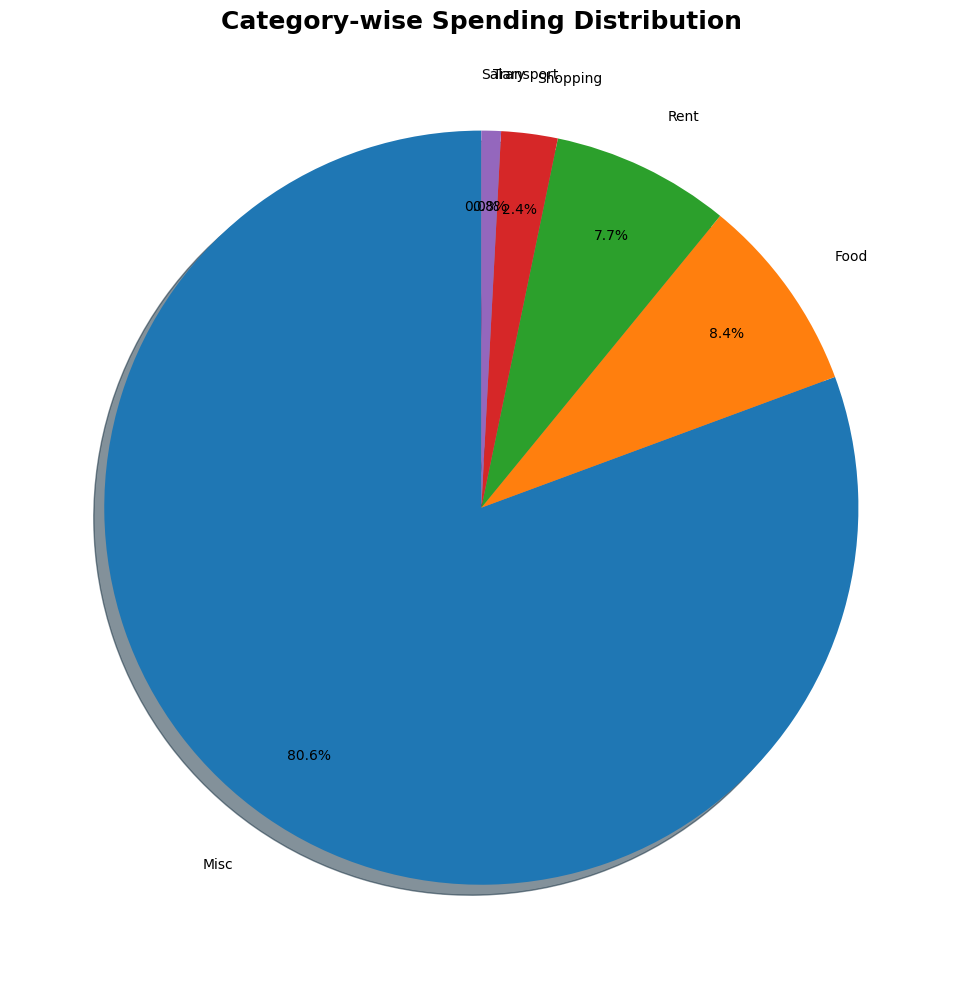

In [ ]:

category_spending = (
    df.groupby('Category')['Withdrawal']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 10))

plt.pie(
    category_spending,
    labels=category_spending.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.8,
    labeldistance=1.15,
    shadow=True
)

plt.title(
    "Category-wise Spending Distribution",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


**spend for food by month analysis dashboard**

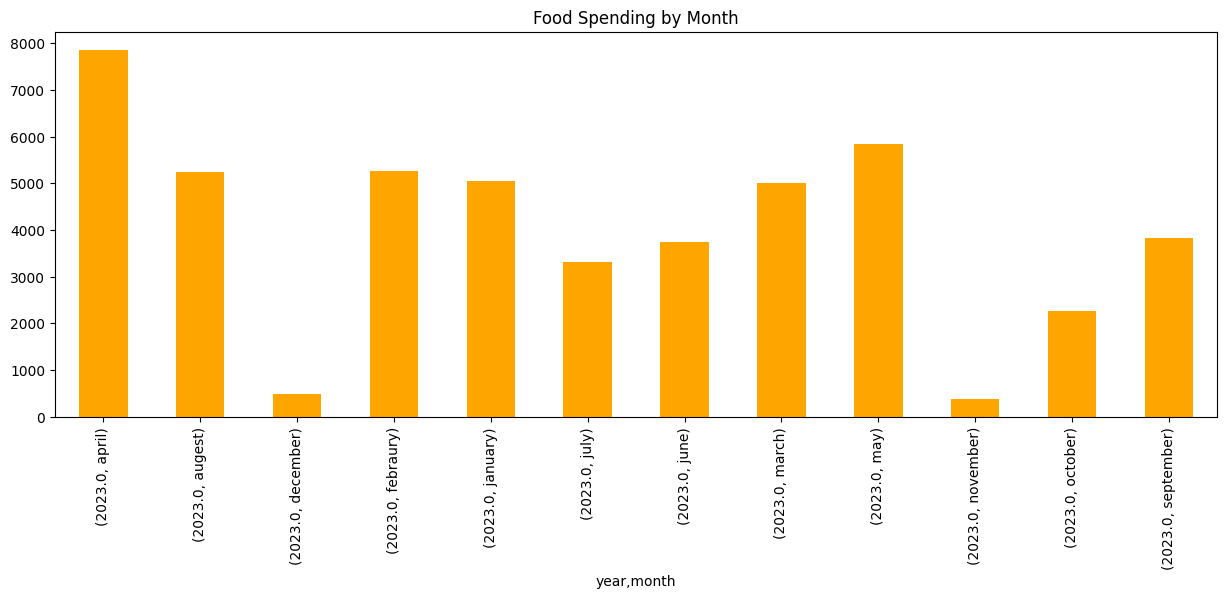

In [ ]:
food_month.plot(
    kind='bar',
    figsize=(15,5),
    color='orange'
)

plt.title("Food Spending by Month")
plt.show()

**withdrawal trend between may to augest analysis dashboard**

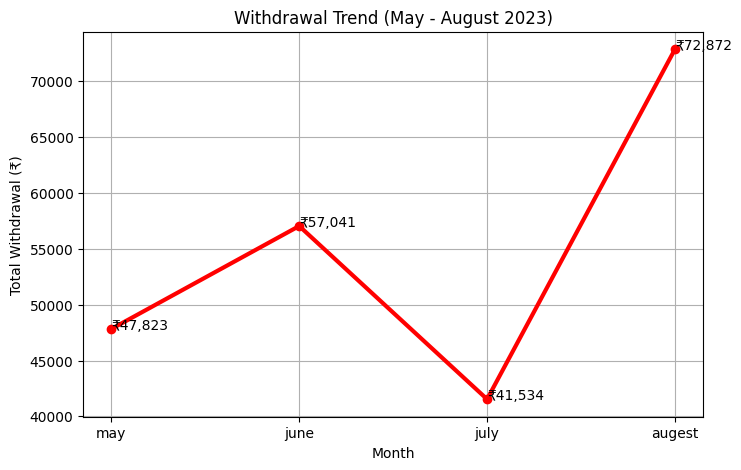

In [ ]:

months = ['may', 'june', 'july', 'augest']

withdrawal_data = (
    df[
        (df['year'] == 2023) &
        (df['month'].isin(months))
    ]
    .groupby('month')['Withdrawal']
    .sum()
    .reindex(months)
)

plt.figure(figsize=(8,5))

plt.plot(
    withdrawal_data.index,
    withdrawal_data.values,
    marker='o',
    linewidth=3,
    color='red'
)

plt.title("Withdrawal Trend (May - August 2023)")
plt.xlabel("Month")
plt.ylabel("Total Withdrawal (₹)")
plt.grid(True)

for i, value in enumerate(withdrawal_data.values):
    plt.text(i, value, f'₹{value:,.0f}')

plt.show()

**deposit analysis between january to april**

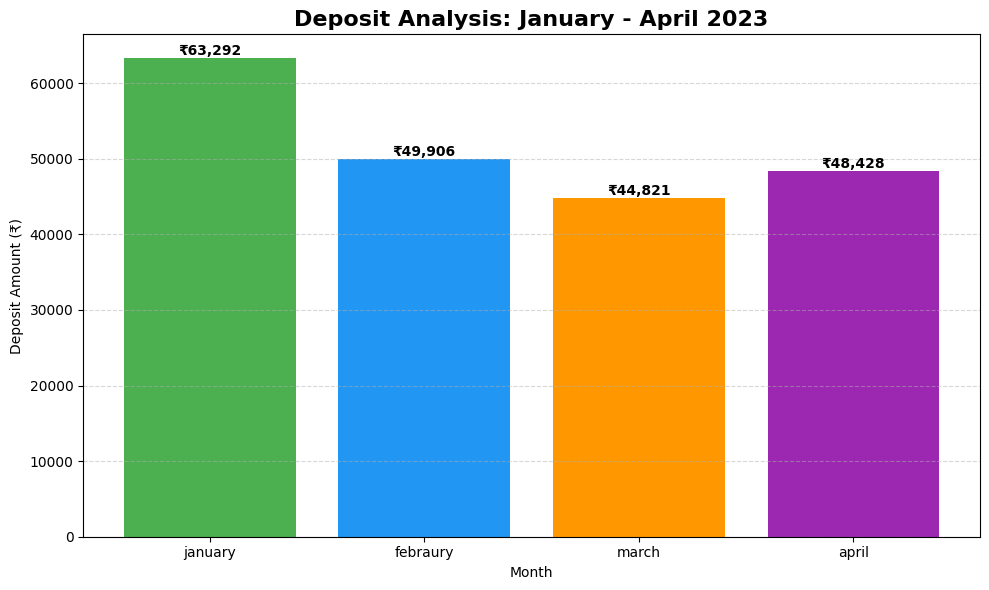

In [ ]:

months = ['january', 'febraury', 'march', 'april']

deposit_data = (
    df[
        (df['year'] == 2023) &
        (df['month'].isin(months))
    ]
    .groupby('month')['Deposit']
    .sum()
    .reindex(months)
)

plt.figure(figsize=(10,6))

bars = plt.bar(
    deposit_data.index,
    deposit_data.values,
    color=['#4CAF50', '#2196F3', '#FF9800', '#9C27B0']
)

plt.title(
    "Deposit Analysis: January - April 2023",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Month")
plt.ylabel("Deposit Amount (₹)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹{height:,.0f}',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**spending for music in year analysis dashboard**

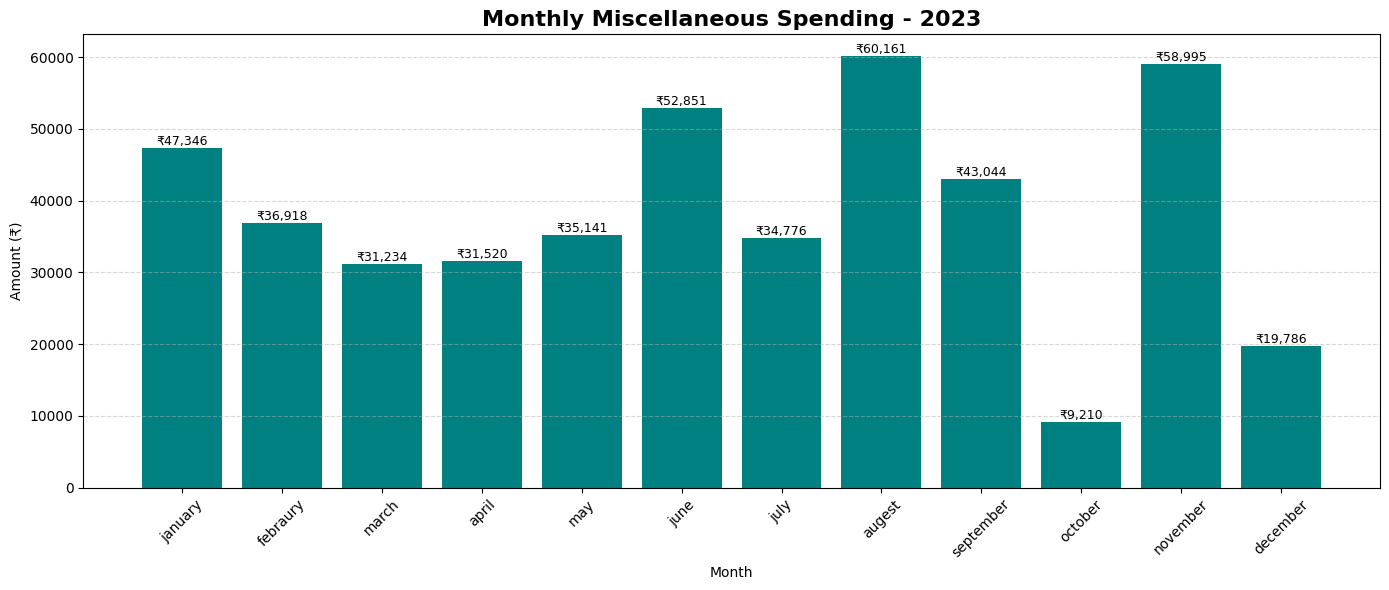

In [ ]:

misc_monthly = (
    df[df['Category'] == 'Misc']
    .groupby('month')['Withdrawal']
    .sum()
)

month_order = [
    'january','febraury','march','april',
    'may','june','july','augest',
    'september','october','november','december'
]

misc_monthly = misc_monthly.reindex(month_order)

plt.figure(figsize=(14,6))

bars = plt.bar(
    misc_monthly.index,
    misc_monthly.values,
    color='teal'
)

plt.title(
    "Monthly Miscellaneous Spending - 2023",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Month")
plt.ylabel("Amount (₹)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹{height:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**deposit vs withdrawal analysis between january to april dashboard**

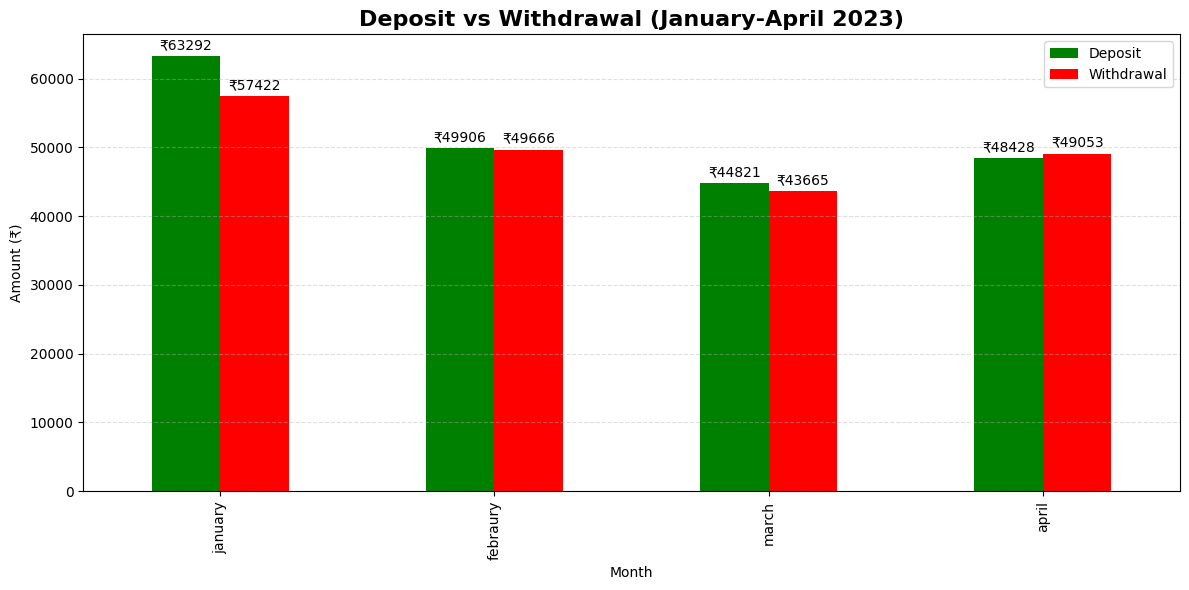

In [ ]:

months = ['january', 'febraury', 'march', 'april']

comparison = (
    df[
        (df['year'] == 2023) &
        (df['month'].isin(months))
    ]
    .groupby('month')
    .agg({
        'Deposit':'sum',
        'Withdrawal':'sum'
    })
    .reindex(months)
)

ax = comparison.plot(
    kind='bar',
    figsize=(12,6),
    color=['green', 'red']
)

plt.title(
    "Deposit vs Withdrawal (January-April 2023)",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Month")
plt.ylabel("Amount (₹)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='₹%.0f',
        padding=3
    )

plt.legend(['Deposit', 'Withdrawal'])

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**savings analysis by using bar chart dashboard**

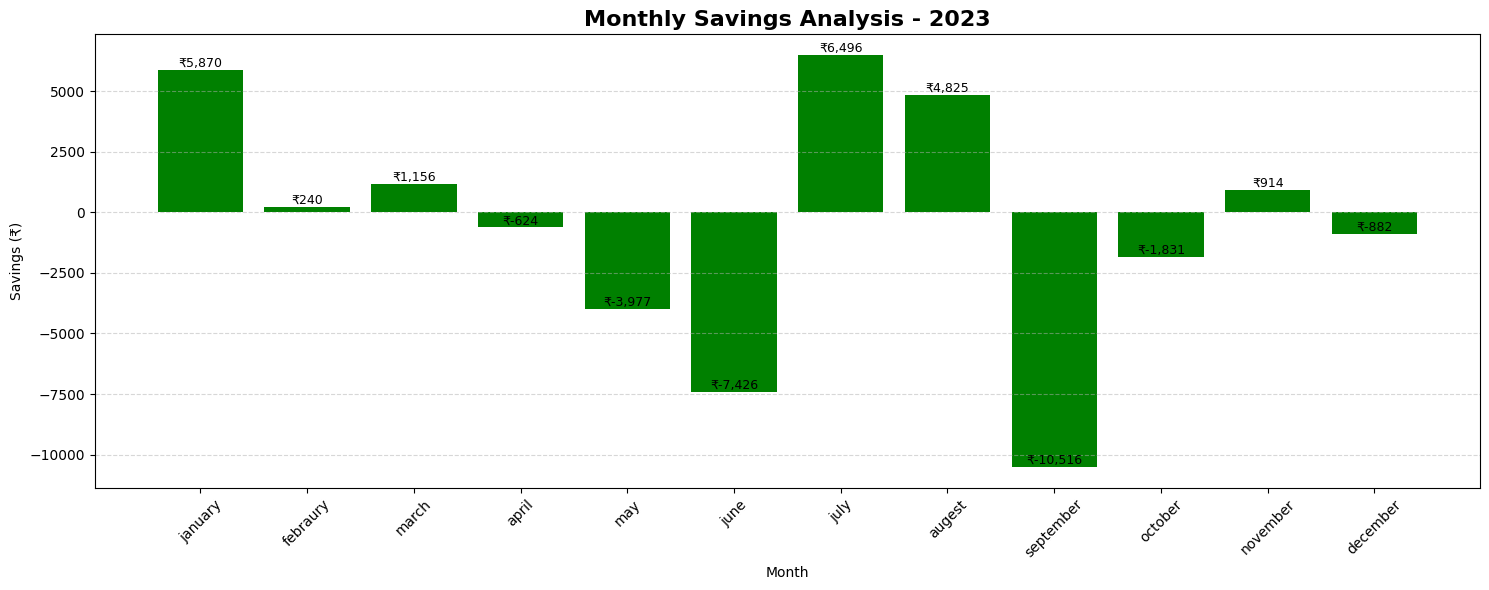

In [ ]:

month_order = [
    'january', 'febraury', 'march', 'april',
    'may', 'june', 'july', 'augest',
    'september', 'october', 'november', 'december'
]

savings = (
    df[df['year'] == 2023]
    .groupby('month')
    .agg({
        'Deposit': 'sum',
        'Withdrawal': 'sum'
    })
)

savings['Savings'] = (
    savings['Deposit'] - savings['Withdrawal']
)

savings = savings.reindex(month_order)

plt.figure(figsize=(15, 6))

bars = plt.bar(
    savings.index,
    savings['Savings'],
    color='green'
)

plt.title(
    "Monthly Savings Analysis - 2023",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Month")
plt.ylabel("Savings (₹)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹{height:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


**monthy savings trend analysis dash board**

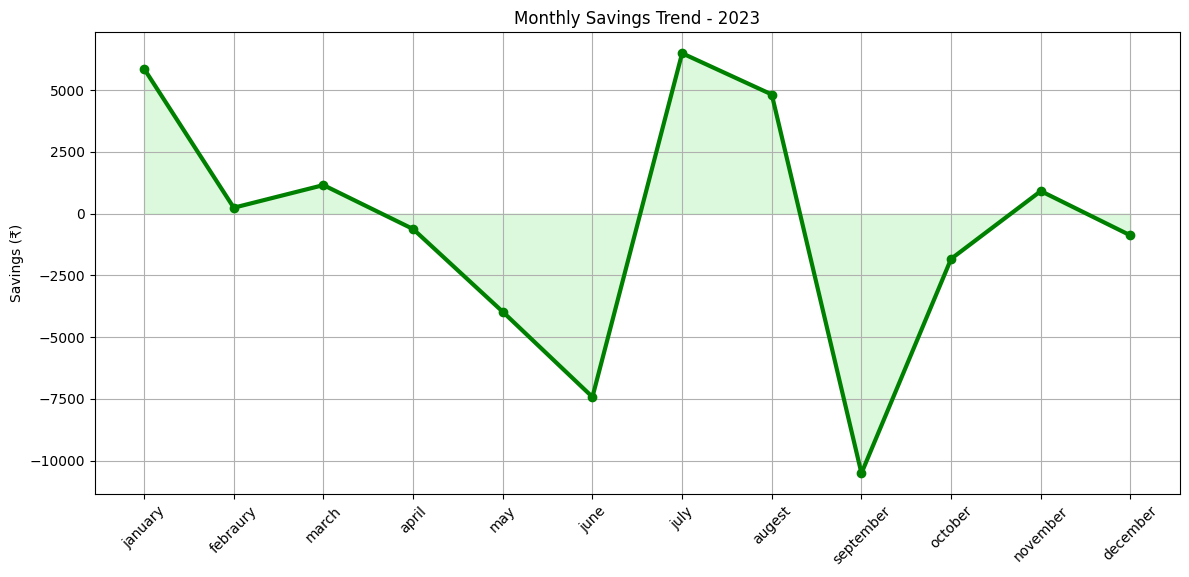

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    savings.index,
    savings['Savings'],
    marker='o',
    linewidth=3,
    color='green'
)

plt.fill_between(
    savings.index,
    savings['Savings'],
    alpha=0.3,
    color='lightgreen'
)

plt.title("Monthly Savings Trend - 2023")
plt.ylabel("Savings (₹)")
plt.xticks(rotation=45)

plt.grid(True)

plt.show()

**spending distribution by category**

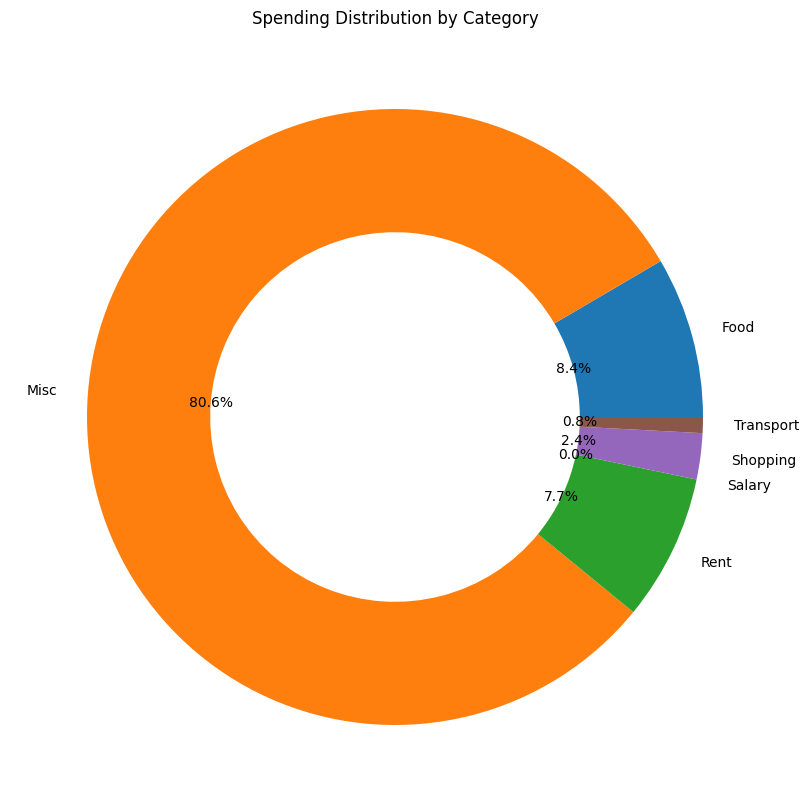

In [ ]:
category_spending = (
    df.groupby('Category')['Withdrawal']
    .sum()
)

plt.figure(figsize=(10,10))

plt.pie(
    category_spending,
    labels=category_spending.index,
    autopct='%1.1f%%',
    wedgeprops={'width':0.4}
)

plt.title("Spending Distribution by Category")

plt.show()

**catagory of spending by using heatmap**

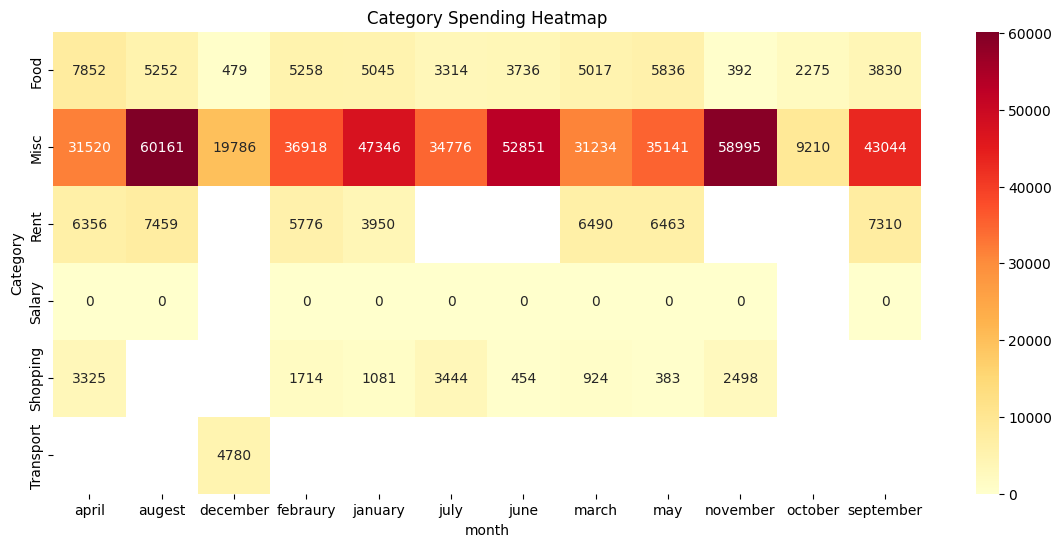

In [ ]:


heat = pd.pivot_table(
    df,
    values='Withdrawal',
    index='Category',
    columns='month',
    aggfunc='sum'
)

plt.figure(figsize=(14,6))

sns.heatmap(
    heat,
    annot=True,
    cmap='YlOrRd',
    fmt='.0f'
)

plt.title("Category Spending Heatmap")

plt.show()